## Calving at Jakobshavn Isbrae, Greenland ##

This notebook has preliminary data analysis for calving events at glacier Jakobshavn Isbrae in Greenland. 

In [ ]:
# import libraries and packages
import os
import glob
import dask
import panel
import shapely
import rasterio
import pandas as pd
import xarray as xr
import numpy as np
import geopandas as gpd
import nisardev as nisar
import grimpfunc as grimp
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.cm as mcm
import matplotlib.ticker as mticker
import matplotlib.dates as mdates
from matplotlib import colors
import cmocean.cm as cm
from shapely.geometry import LineString, Polygon, Point
from matplotlib.ticker import FuncFormatter
from shapely.affinity import translate
from shapely.ops import (split, polygonize_full, linemerge, unary_union,)
from dask.diagnostics import ProgressBar

# autoreload of modules
%load_ext autoreload
%autoreload 2

### BedMachine Ice Thickness vs. Calving ### 

This section will focus on looking at BedMachine ice thickness along the central flowline:
1. For every 6/12-day terminus position, you can find the ice thickness and water depth (if not floating)
2. Measuring calving event size in length X as a fraction of ice thickness H - where _X/H_ is a statistical variable

If you have a ratio _X/H_ where X ~ H you can explore the relationship between these two and compare across glaciers, i.e., if ratio ~ 1 compare to not  ~ 1 - can look across locations and times


In [56]:
# load in data - set paths
terminus_path = "/Users/sofiasuhinin/Desktop/GrIS_Calving/Jakobshavn-Isbrae-CalvingStatistics/JakobshavnIsbrae_data.gpkg"
terminus = gpd.read_file(terminus_path)

centerline_path = "/Users/sofiasuhinin/Desktop/GrIS_Calving/data/flowlines/JakobshavnIsbraeCenterline.shp"
centerline = gpd.read_file(centerline_path)
centerline = centerline.to_crs("EPSG: 3413")
centerline_shape = centerline.geometry.iloc[0]

bedmachine_path = "/Users/sofiasuhinin/Desktop/GrIS_Calving/data/BedMachine/JakobshavnIsbraeBedMachineV7.nc"
bedmachine = xr.open_dataset(bedmachine_path)

In [68]:
# consistent plotting properties
plotprops = dict(
    figsize=(10, 5),fontsize=14, titlesize=18, titleweight = "bold", labelsize=14, labelweight= "bold", ticksize=14, legendsize=8, linewidth=1, markersize=6, grid=True, alpha=0.25,
    #background colour for plots
    facecolor="#E7E7E7CC", 
    #map labels
    xlabel = "Easting [m]", ylabel = "Northing [m]",
    #scientific notation for axes
    map_scilimits=(6,6),
    )

In [46]:
bedmachine

<xarray.Dataset> Size: 2MB
Dimensions:    (x: 273, y: 300)
Coordinates:
  * x          (x) int32 1kB -205475 -205325 -205175 ... -164975 -164825 -164675
  * y          (y) int32 1kB -2248925 -2249075 -2249225 ... -2293625 -2293775
Data variables:
    mapping    |S1 1B ...
    mask       (y, x) int8 82kB ...
    surface    (y, x) float32 328kB ...
    thickness  (y, x) float32 328kB ...
    bed        (y, x) float32 328kB ...
    errbed     (y, x) float32 328kB ...
    source     (y, x) int8 82kB ...
    dataid     (y, x) int8 82kB ...
    geoid      (y, x) float32 328kB ...
    rgi        (y, x) int8 82kB ...
Attributes: (12/19)
    Conventions:                 CF-1.7, ACDD-1.3
    title:                       BedMachine Greenland v7
    creator_name:                Mathieu Morlighem
    creator_email:               mathieu.morlighem@dartmouth.edu
    creator_institution:         Department of Earth and Planetary Sciences, ...
    product_version:             v7.0
    ...                          ...
    references:                  Morlighem M. et al., (2017), BedMachine v3: ...
    keywords:                    EARTH SCIENCE > CRYOSPHERE > GLACIERS/ICE SH...
    summary:                     This dataset contains a bed topography/bathy...
    time_coverage_start:         1970-01-01
    time_coverage_end:           2019-10-01
    nominal_year:                2008

In [ ]:
print(bedmachine.attrs)
print(bedmachine.geospatial_bounds_crs)
print(centerline.crs)

{'Conventions': 'CF-1.7, ACDD-1.3', 'title': 'BedMachine Greenland v7', 'creator_name': 'Mathieu Morlighem', 'creator_email': 'mathieu.morlighem@dartmouth.edu', 'creator_institution': 'Department of Earth and Planetary Sciences, Dartmouth', 'product_version': 'v7.0', 'date_modified': '2026-10-06T07:41:18', 'geospatial_bounds_crs': 'EPSG:3413', 'geospatial_lat_resolution': '150 meters', 'geospatial_lon_resolution': '150 meters', 'sea_water_density (kg m-3)': np.float64(1023.0), 'ice_density (kg m-3)': np.float64(917.0), 'license': 'No restrictions on access or use', 'references': 'Morlighem M. et al., (2017), BedMachine v3: Complete bed topography and ocean bathymetry mapping of Greenland from multi-beam echo sounding combined with mass conservation, Geophys. Res. Lett., 44, doi:10.1002/2017GL074954. (http://onlinelibrary.wiley.com/doi/10.1002/2017GL074954/full)', 'keywords': 'EARTH SCIENCE > CRYOSPHERE > GLACIERS/ICE SHEETS > GLACIER TOPOGRAPHY/ICE SHEET TOPOGRAPHY', 'summary': 'This d

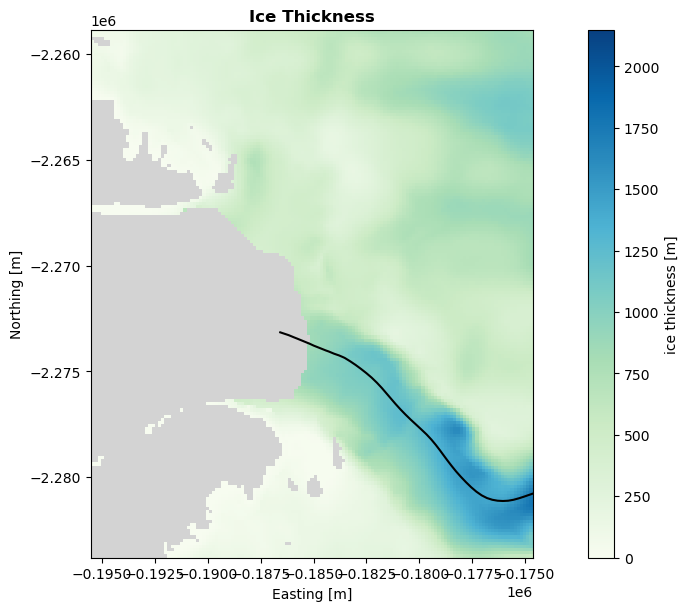

In [41]:
# plotting properties ( 0 m = grey - better for visual)
cmap = plt.colormaps["GnBu"].copy()
cmap.set_bad("lightgrey")
thickness = bedmachine["thickness"].where(bedmachine["thickness"]> 0)

fig, ax = plt.subplots(figsize=(8, 6), constrained_layout=True)

thickness.plot( ax=ax, cmap=cmap, vmin = 0)
centerline.plot(ax=ax, color = "black", linewidth = 1.5)
ax.set_title("Ice Thickness", fontweight = "bold")
ax.set_xlabel("Easting [m]")
ax.set_ylabel("Northing [m]")
ax.ticklabel_format(axis="both", style="sci", scilimits=(6,6)) 

#zoom
xmin, ymin, xmax, ymax = terminus.total_bounds
zoom = 5000
ax.set_xlim(xmin - zoom, xmax + zoom)
ax.set_ylim(ymin - zoom, ymax + zoom)
ax.set_aspect("equal")

plt.show()

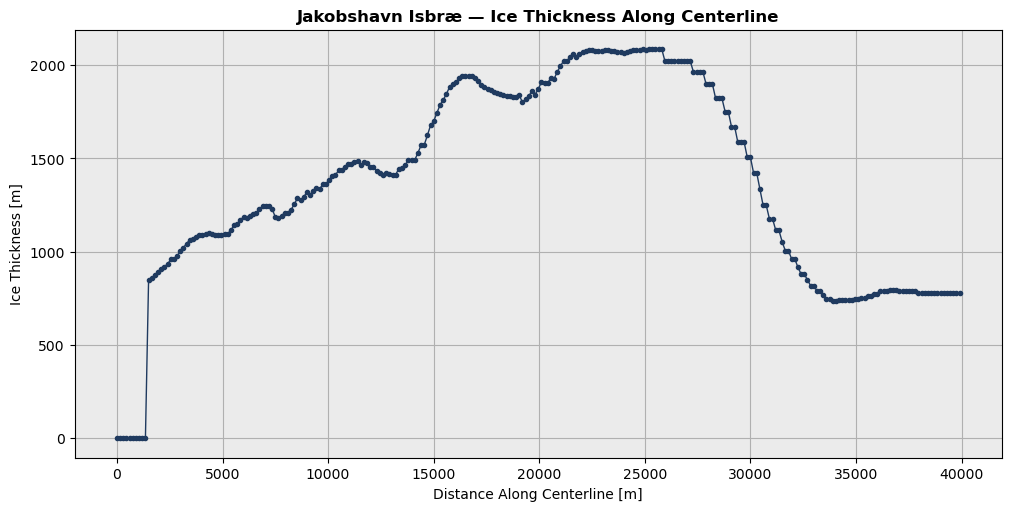

In [75]:
# sample ice thickness along the centerline 

# sample every 150 meters 
spacing = 150 # 150 m bc the BedMachine res is 150 m

# generate distances spaced every 100 m 
distances = np.arange(0, 40000, spacing)

# let these be x and y points 
points = [centerline_shape.interpolate(d)for d in distances]
x_points = np.array([point.x for point in points])
y_points = np.array([point.y for point in points])

# use nearest ice thickness to x/ypoint  - use .sel() 
thickness_centerline = bedmachine["thickness"].sel(x = xr.DataArray(x_points, dims="distance"), y = xr.DataArray(y_points, dims="distance"), method="nearest")
thickness_profile = pd.DataFrame({"distance_m": distances, "x": x_points, "y": y_points, "thickness_m": thickness_centerline.values})

fig, ax = plt.subplots(figsize = (10,5), constrained_layout = True)
ax.plot(thickness_profile["distance_m"], thickness_profile["thickness_m"], color="#1f3a5f", linewidth = plotprops["linewidth"], marker = "o", markersize = 3)
ax.set_xlabel("Distance Along Centerline [m]")
ax.set_ylabel("Ice Thickness [m]")
ax.set_title("Jakobshavn Isbræ — Ice Thickness Along Centerline", fontweight=plotprops["titleweight"])
ax.set_facecolor(plotprops["facecolor"])
ax.grid(True)
plt.show()